## Circuit-Level Quantum Error Correction with Stim and PyMatching

This notebook simulates repeated quantum error-correction cycles using Stim and decodes the resulting detection events using PyMatching.

Unlike the previous analytical bit-flip model, this simulation includes noisy circuit operations, repeated parity measurements and measurement errors.

The workflow is:

1. Generate a noisy repetition-code memory circuit.
2. Sample detector events and logical-observable changes.
3. Construct a detector error model.
4. Build a minimum-weight perfect-matching decoder.
5. Compare predicted and actual logical-observable changes.
6. Measure logical failure probability and decoder performance.

In [119]:
# Import standard libraries, scientific tools, Stim, and PyMatching
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymatching
import stim

# Configure project output directories and global random seed
PROJECT_DIR = Path(
    r"C:\Users\Karthi\Qauntum"
)

FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SEED = 42

print("Stim version:", stim.__version__)
print("PyMatching version:", pymatching.__version__)
print("Circuit-level QEC environment ready.")

Stim version: 1.16.0
PyMatching version: 2.4.0
Circuit-level QEC environment ready.


In [120]:
# Set baseline repetition-code parameters and circuit-level physical error rate
distance = 3
rounds = 3
physical_error_probability = 0.001


In [121]:
# Generate a noisy distance-3 repetition-code memory circuit with uniform circuit-level noise
repetition_circuit = stim.Circuit.generated(
    "repetition_code:memory",
    distance=distance,
    rounds=rounds,
    after_clifford_depolarization=(
        physical_error_probability
    ),
    before_round_data_depolarization=(
        physical_error_probability
    ),
    before_measure_flip_probability=(
        physical_error_probability
    ),
    after_reset_flip_probability=(
        physical_error_probability
    ),
)

In [122]:
# Print circuit resource counts (physical qubits, measurements, detectors, and observables)
print("Number of qubits:", repetition_circuit.num_qubits)
print(
    "Number of measurements:",
    repetition_circuit.num_measurements,
)
print(
    "Number of detectors:",
    repetition_circuit.num_detectors,
)
print(
    "Number of observables:",
    repetition_circuit.num_observables,
)

Number of qubits: 5
Number of measurements: 9
Number of detectors: 8
Number of observables: 1


In [123]:
# Print the raw Stim circuit instructions, noise channels, and detector annotations
print(repetition_circuit)

R 0 1 2 3 4
X_ERROR(0.001) 0 1 2 3 4
TICK
DEPOLARIZE1(0.001) 0 2 4
CX 0 1 2 3
DEPOLARIZE2(0.001) 0 1 2 3
TICK
CX 2 1 4 3
DEPOLARIZE2(0.001) 2 1 4 3
TICK
X_ERROR(0.001) 1 3
MR 1 3
X_ERROR(0.001) 1 3
DETECTOR(1, 0) rec[-2]
DETECTOR(3, 0) rec[-1]
REPEAT 2 {
    TICK
    DEPOLARIZE1(0.001) 0 2 4
    CX 0 1 2 3
    DEPOLARIZE2(0.001) 0 1 2 3
    TICK
    CX 2 1 4 3
    DEPOLARIZE2(0.001) 2 1 4 3
    TICK
    X_ERROR(0.001) 1 3
    MR 1 3
    X_ERROR(0.001) 1 3
    SHIFT_COORDS(0, 1)
    DETECTOR(1, 0) rec[-2] rec[-4]
    DETECTOR(3, 0) rec[-1] rec[-3]
}
X_ERROR(0.001) 0 2 4
M 0 2 4
DETECTOR(1, 1) rec[-2] rec[-3] rec[-5]
DETECTOR(3, 1) rec[-1] rec[-2] rec[-4]
OBSERVABLE_INCLUDE(0) rec[-1]


In [124]:
# Export the generated Stim circuit to disk for reproducibility
stim_circuit_path = (
    RESULTS_DIR
    / "repetition_code_d3_r3.stim"
)

repetition_circuit.to_file(
    stim_circuit_path
)

print(
    f"Saved Stim circuit to: "
    f"{stim_circuit_path}"
)

Saved Stim circuit to: C:\Users\Karthi\Qauntum\results\repetition_code_d3_r3.stim


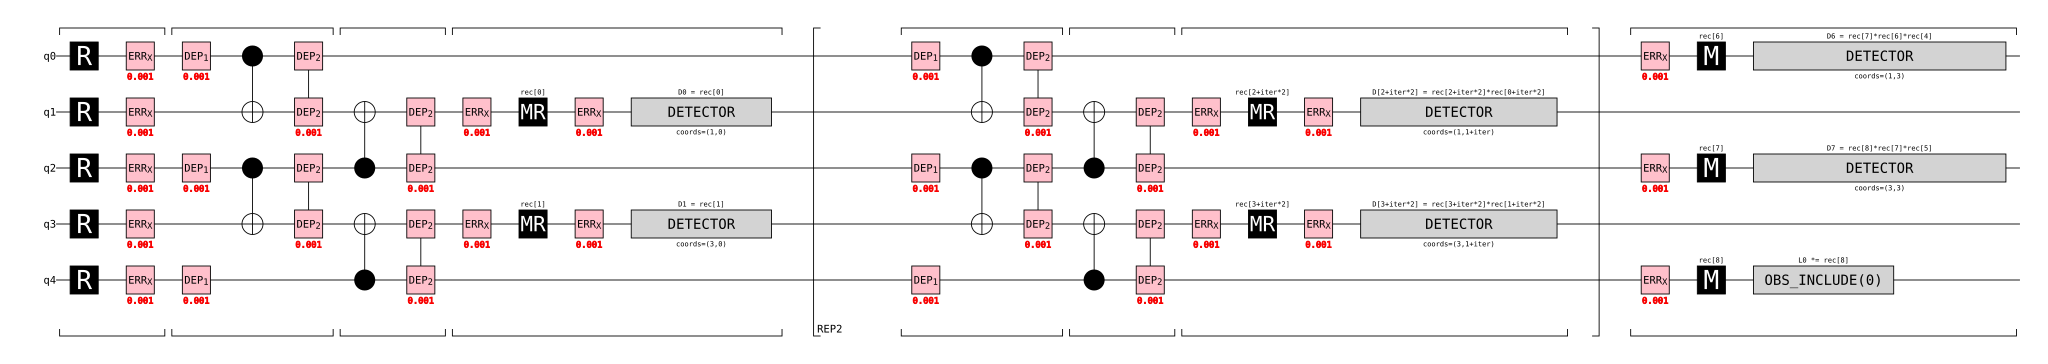

In [125]:
# Render an interactive SVG timeline diagram of gates, noise channels, and detectors
repetition_circuit.diagram(
    "timeline-svg"
)

In [126]:
# Compile a fast detector sampler from the Stim circuit
detector_sampler = (
    repetition_circuit
    .compile_detector_sampler(
        seed=SEED
    )
)

In [127]:
# Sample a small batch of 10 shots separating detector syndromes from true logical flips
small_sample_size = 10

detection_events, actual_observables = (
    detector_sampler.sample(
        shots=small_sample_size,
        separate_observables=True,
    )
)

In [128]:
# Verify output array dimensions: (shots, num_detectors) and (shots, num_observables)
print(
    "Detection-event array shape:",
    detection_events.shape,
)

print(
    "Observable array shape:",
    actual_observables.shape,
)

Detection-event array shape: (10, 8)
Observable array shape: (10, 1)


In [129]:
# Display binary detector syndrome rows and corresponding logical observable flips
print("Detection events:")
print(
    detection_events.astype(int)
)

print("\nActual logical-observable flips:")
print(
    actual_observables.astype(int)
)

Detection events:
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

Actual logical-observable flips:
[[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]


In [130]:
# Print the total triggered detectors and logical flip status for each sampled shot
detection_event_counts = (
    detection_events.sum(
        axis=1
    )
)

for shot_index, event_count in enumerate(
    detection_event_counts
):
    print(
        f"Shot {shot_index:2d}: "
        f"{event_count} detection events | "
        f"logical flip = "
        f"{int(actual_observables[shot_index, 0])}"
    )

Shot  0: 0 detection events | logical flip = 0
Shot  1: 0 detection events | logical flip = 0
Shot  2: 0 detection events | logical flip = 0
Shot  3: 0 detection events | logical flip = 0
Shot  4: 0 detection events | logical flip = 0
Shot  5: 0 detection events | logical flip = 0
Shot  6: 0 detection events | logical flip = 0
Shot  7: 0 detection events | logical flip = 0
Shot  8: 0 detection events | logical flip = 0
Shot  9: 0 detection events | logical flip = 0


In [131]:
# Sample 1,000 shots to inspect how often detection events and logical flips occur
inspection_shots = 1_000

inspection_detections, inspection_observables = (
    detector_sampler.sample(
        shots=inspection_shots,
        separate_observables=True,
    )
)

shots_with_detection_events = np.count_nonzero(
    inspection_detections.any(
        axis=1
    )
)

shots_with_logical_flips = np.count_nonzero(
    inspection_observables[:, 0]
)

print(
    f"Shots with at least one detection event: "
    f"{shots_with_detection_events:,} / "
    f"{inspection_shots:,}"
)

print(
    f"Shots with an actual logical flip: "
    f"{shots_with_logical_flips:,} / "
    f"{inspection_shots:,}"
)

Shots with at least one detection event: 24 / 1,000
Shots with an actual logical flip: 4 / 1,000


In [132]:
# Extract a graph-like detector error model (DEM) mapping physical faults to detector pairs
detector_error_model = (
    repetition_circuit.detector_error_model(
        decompose_errors=True
    )
)

In [133]:
# Display error mechanisms, probabilities, and detector coordinates in the DEM
print(detector_error_model)

error(0.001931182734310662) D0
error(0.001931182734310662) D0 D1
error(0.002263671931417261) D0 D2
error(0.0005333333333331479) D0 D3
error(0.002263671931417261) D1 D3
error(0.001931182734310662) D1 L0
error(0.001199288888888706) D2
error(0.001199288888888706) D2 D3
error(0.002263671931417261) D2 D4
error(0.0005333333333331479) D2 D5
error(0.0002667378157289138) D2 ^ D0
error(0.002263671931417261) D3 D5
error(0.001199288888888706) D3 L0
error(0.0002667378157289138) D3 L0 ^ D1 L0
error(0.001199288888888706) D4
error(0.001199288888888706) D4 D5
error(0.002263671931417261) D4 D6
error(0.0005333333333331479) D4 D7
error(0.0002667378157289138) D4 ^ D2
error(0.002263671931417261) D5 D7
error(0.001199288888888706) D5 L0
error(0.0002667378157289138) D5 L0 ^ D3 L0
error(0.001266204340097456) D6
error(0.001266204340097456) D6 D7
error(0.0002667378157289138) D6 ^ D4
error(0.001266204340097456) D7 L0
error(0.0002667378157289138) D7 L0 ^ D5 L0
detector(1, 0) D0
detector(3, 0) D1
shift_detectors(0, 

In [134]:
# Save the detector error model (.dem) to disk
detector_error_model_path = (
    RESULTS_DIR
    / "repetition_code_d3_r3.dem"
)

detector_error_model.to_file(
    detector_error_model_path
)

print(
    f"Saved detector error model to: "
    f"{detector_error_model_path}"
)

Saved detector error model to: C:\Users\Karthi\Qauntum\results\repetition_code_d3_r3.dem


In [135]:
# Find the minimum-weight chain of graph-like faults that causes an undetected logical error
shortest_logical_error = (
    repetition_circuit
    .shortest_graphlike_error()
)

print(shortest_logical_error)

[stim.ExplainedError(dem_error_terms=(stim.DemTargetWithCoords(dem_target=stim.DemTarget('D0'), coords=[1, 0]),), circuit_error_locations=(stim.CircuitErrorLocation(tick_offset=1, flipped_pauli_product=(stim.GateTargetWithCoords(stim.target_x(0), []),stim.GateTargetWithCoords(stim.target_x(1), []),), flipped_measurement=stim.FlippedMeasurement(
    record_index=None,
    observable=(),
), instruction_targets=stim.CircuitTargetsInsideInstruction(gate='DEPOLARIZE2', args=[0.001], target_range_start=0, target_range_end=2, targets_in_range=(stim.GateTargetWithCoords(0, []),stim.GateTargetWithCoords(1, []),)), stack_frames=(stim.CircuitErrorLocationStackFrame(
    instruction_offset=5,
    iteration_index=0,
    instruction_repetitions_arg=0,
),)),stim.CircuitErrorLocation(tick_offset=1, flipped_pauli_product=(stim.GateTargetWithCoords(stim.target_x(0), []),stim.GateTargetWithCoords(stim.target_y(1), []),), flipped_measurement=stim.FlippedMeasurement(
    record_index=None,
    observable=(

In [136]:
# Print the effective code distance (number of faults in the shortest logical error)
print(
    "Graph-like error mechanisms in the "
    "shortest logical error:",
    len(shortest_logical_error),
)

Graph-like error mechanisms in the shortest logical error: 3


In [137]:
# Build a Minimum-Weight Perfect Matching (MWPM) decoder from the detector error model
matching_decoder = (
    pymatching.Matching
    .from_detector_error_model(
        detector_error_model
    )
)

In [138]:
# Inspect the matching graph size (nodes/detectors, weighted edges, and logical fault IDs)
print(
    "Matching graph detectors:",
    matching_decoder.num_detectors,
)

print(
    "Matching graph edges:",
    matching_decoder.num_edges,
)

print(
    "Matching graph fault IDs:",
    matching_decoder.num_fault_ids,
)

Matching graph detectors: 8
Matching graph edges: 21
Matching graph fault IDs: 1


In [139]:
# Decode the 10-shot syndrome batch to predict logical observable flips
predicted_observables = (
    matching_decoder.decode_batch(
        detection_events
    )
)

In [140]:
# Compare decoder predictions against actual simulated logical flips
print("Predicted logical-observable flips:")
print(
    predicted_observables.astype(int)
)

print("\nActual logical-observable flips:")
print(
    actual_observables.astype(int)
)

Predicted logical-observable flips:
[[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]

Actual logical-observable flips:
[[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]


In [141]:
# Verify prediction and ground-truth array shapes match
print(
    "Predicted shape:",
    predicted_observables.shape,
)

print(
    "Actual shape:",
    actual_observables.shape,
)

assert (
    predicted_observables.shape
    == actual_observables.shape
)

Predicted shape: (10, 1)
Actual shape: (10, 1)


In [142]:
# Count shots where the decoder's logical prediction disagreed with the actual flip
decoding_failures = np.any(
    predicted_observables
    != actual_observables,
    axis=1,
)

print(
    "Decoding failures in small sample:",
    int(decoding_failures.sum()),
)

Decoding failures in small sample: 0


In [143]:
# Set sample size for large-scale Monte Carlo benchmarking
number_of_shots = 100_000

In [144]:
# Benchmark Stim circuit sampling runtime across 100,000 shots
sample_start = perf_counter()

large_detection_events, large_actual_observables = (
    detector_sampler.sample(
        shots=number_of_shots,
        separate_observables=True,
    )
)

sample_end = perf_counter()

In [145]:
# Benchmark PyMatching batch decoding runtime across 100,000 shots
decode_start = perf_counter()

large_predicted_observables = (
    matching_decoder.decode_batch(
        large_detection_events
    )
)

decode_end = perf_counter()

In [146]:
# Compute total logical decoding failures and estimated logical failure probability
large_decoding_failures = np.any(
    large_predicted_observables
    != large_actual_observables,
    axis=1,
)

logical_failure_count = int(
    large_decoding_failures.sum()
)

logical_failure_probability = (
    logical_failure_count
    / number_of_shots
)

In [147]:
# Display logical failure rate, sampling/decoding runtimes, and throughput metrics
sampling_time = (
    sample_end - sample_start
)

decoding_time = (
    decode_end - decode_start
)

print(
    f"Shots: {number_of_shots:,}"
)

print(
    f"Logical decoding failures: "
    f"{logical_failure_count:,}"
)

print(
    f"Estimated logical failure probability: "
    f"{logical_failure_probability:.6e}"
)

print(
    f"Sampling time: "
    f"{sampling_time:.6f} seconds"
)

print(
    f"Decoding time: "
    f"{decoding_time:.6f} seconds"
)

print(
    f"Sampling throughput: "
    f"{number_of_shots / sampling_time:,.0f} "
    "shots/s"
)

print(
    f"Decoding throughput: "
    f"{number_of_shots / decoding_time:,.0f} "
    "shots/s"
)

print(
    f"Mean decoder time: "
    f"{1e6 * decoding_time / number_of_shots:.3f} "
    "microseconds/shot"
)

Shots: 100,000
Logical decoding failures: 5
Estimated logical failure probability: 5.000000e-05
Sampling time: 0.001406 seconds
Decoding time: 0.002467 seconds
Sampling throughput: 71,138,929 shots/s
Decoding throughput: 40,538,351 shots/s
Mean decoder time: 0.025 microseconds/shot


In [148]:
# Compute a 95% confidence interval (or rule-of-three upper bound if zero failures occurred)
if logical_failure_count > 0:
    logical_standard_error = np.sqrt(
        logical_failure_probability
        * (
            1.0
            - logical_failure_probability
        )
        / number_of_shots
    )

    confidence_lower = max(
        0.0,
        logical_failure_probability
        - 1.96 * logical_standard_error,
    )

    confidence_upper = min(
        1.0,
        logical_failure_probability
        + 1.96 * logical_standard_error,
    )

    print(
        f"Approximate 95% interval: "
        f"[{confidence_lower:.6e}, "
        f"{confidence_upper:.6e}]"
    )
else:
    upper_bound = (
        3.0 / number_of_shots
    )

    print(
        "No decoding failures were observed."
    )

    print(
        "Approximate 95% upper bound from "
        f"the rule of three: {upper_bound:.6e}"
    )

Approximate 95% interval: [6.174163e-06, 9.382584e-05]


In [149]:
# Summarize summary statistics for triggered detection events per shot
events_per_shot = (
    large_detection_events.sum(
        axis=1
    )
)

event_statistics = {
    "mean": float(
        events_per_shot.mean()
    ),
    "median": float(
        np.median(events_per_shot)
    ),
    "maximum": int(
        events_per_shot.max()
    ),
    "shots_with_zero_events": int(
        np.count_nonzero(
            events_per_shot == 0
        )
    ),
}

event_statistics

{'mean': 0.05528, 'median': 0.0, 'maximum': 4, 'shots_with_zero_events': 96701}

In [150]:
# Compare average detection event counts between successful and failed decoding shots
successful_event_counts = events_per_shot[
    ~large_decoding_failures
]

failed_event_counts = events_per_shot[
    large_decoding_failures
]

print(
    "Mean events in successful shots:",
    successful_event_counts.mean(),
)

if logical_failure_count > 0:
    print(
        "Mean events in failed shots:",
        failed_event_counts.mean(),
    )

Mean events in successful shots: 0.055162758137906893
Mean events in failed shots: 2.4


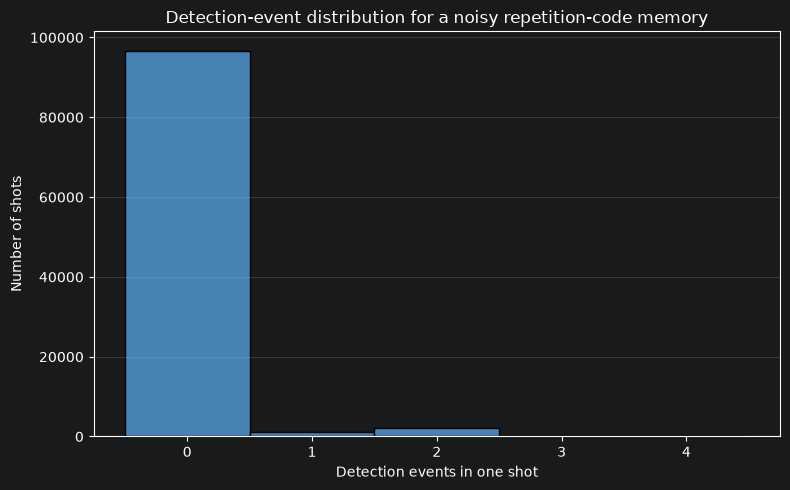

Saved figure to: C:\Users\Karthi\Qauntum\figures\stim_detection_event_distribution.png


In [151]:
# Plot and save the histogram of detection events per shot
maximum_events_to_plot = min(
    int(events_per_shot.max()),
    20,
)

histogram_bins = np.arange(
    -0.5,
    maximum_events_to_plot + 1.5,
    1.0,
)

figure, axis = plt.subplots(
    figsize=(8, 5)
)

axis.hist(
    events_per_shot[
        events_per_shot
        <= maximum_events_to_plot
        ],
    bins=histogram_bins,
    color="steelblue",
    edgecolor="black",
)

axis.set_xlabel(
    "Detection events in one shot"
)

axis.set_ylabel(
    "Number of shots"
)

axis.set_title(
    "Detection-event distribution for a "
    "noisy repetition-code memory"
)

axis.set_xticks(
    range(
        maximum_events_to_plot + 1
    )
)

axis.grid(
    axis="y",
    alpha=0.3,
)

figure.tight_layout()

event_distribution_path = (
        FIGURE_DIR
        / "stim_detection_event_distribution.png"
)

figure.savefig(
    event_distribution_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{event_distribution_path}"
)

In [152]:
#Compile circuit parameters, failure rates, and decoder performance into a summary CSV
circuit_level_summary = pd.DataFrame(
    [
        {
            "code": "repetition_code:memory",
            "distance": distance,
            "rounds": rounds,
            "physical_error_probability": (
                physical_error_probability
            ),
            "number_of_qubits": (
                repetition_circuit.num_qubits
            ),
            "number_of_detectors": (
                repetition_circuit.num_detectors
            ),
            "number_of_observables": (
                repetition_circuit.num_observables
            ),
            "shots": number_of_shots,
            "logical_failures": (
                logical_failure_count
            ),
            "logical_failure_probability": (
                logical_failure_probability
            ),
            "sampling_time_seconds": (
                sampling_time
            ),
            "decoding_time_seconds": (
                decoding_time
            ),
            "sampling_throughput_shots_per_second": (
                    number_of_shots / sampling_time
            ),
            "decoding_throughput_shots_per_second": (
                    number_of_shots / decoding_time
            ),
            "decoder_microseconds_per_shot": (
                    1e6
                    * decoding_time
                    / number_of_shots
            ),
            "mean_detection_events_per_shot": (
                events_per_shot.mean()
            ),
        }
    ]
)

circuit_level_summary_path = (
        RESULTS_DIR
        / "stim_pymatching_repetition_summary.csv"
)

circuit_level_summary.to_csv(
    circuit_level_summary_path,
    index=False,
)

circuit_level_summary

,code,distance,rounds,physical_error_probability,number_of_qubits,number_of_detectors,number_of_observables,shots,logical_failures,logical_failure_probability,sampling_time_seconds,decoding_time_seconds,sampling_throughput_shots_per_second,decoding_throughput_shots_per_second,decoder_microseconds_per_shot,mean_detection_events_per_shot
0,repetition_code:memory,3,3,0.001,5,8,1,100000,5,0.00005,0.001406,0.002467,7.113893e+07,4.053835e+07,0.024668,0.05528


# Circuit-level decoding results


Stim generated a noisy repetition-code memory experiment containing repeated syndrome measurements, detector annotations and a logical observable. Detection events represented changes in parity constraints rather than raw syndrome values.


The detector error model mapped physical fault mechanisms to their associated detector events and possible logical-observable changes. PyMatching converted this model into a matching graph and used minimum-weight perfect matching to predict the most likely logical correction for each shot.


A logical decoding failure was recorded whenever the predicted observable change differed from the actual logical-observable change produced by the simulation.


This circuit-level model is more realistic than the earlier independent data-bit model because it includes errors in Clifford gates, data qubits between rounds, measurement and reset. It also includes repeated syndrome extraction, allowing faults to be localised in both space and time.


The measured decoding throughput describes batched software performance on the current CPU. It does not represent the latency of an FPGA or ASIC real-time decoder. Batch throughput and single-shot latency should be measured separately because a decoder can achieve high aggregate throughput while still failing a strict per-round latency deadline.


The logical-failure estimate remains subject to Monte Carlo uncertainty. If few failures are observed, substantially more shots or specialised rare-event methods are required for a precise estimate.


# Code-Distance and Physical-Error-Rate Scaling


This notebook investigates how the logical failure probability of a noisy repetition-code memory changes with:


- code distance;


- physical circuit-level error probability;


- number of syndrome-extraction rounds;


- detector-graph size;


- classical decoding time.


For a distance-d repetition code, increasing the distance increases the number of physical data qubits and allows the code to correct more bit-flip errors.


Under sufficiently low physical noise, increasing code distance should reduce the logical failure probability. Above the code's threshold region, increasing distance may no longer provide an advantage.


In [153]:
def create_repetition_memory_circuit(
    distance,
    rounds,
    physical_error_probability,
):
    # The same circuit-level error probability is used for:
    #
    #     - Clifford-gate depolarisation;
    #     - data errors before each round;
    #     - measurement flips;
    #     - reset flips.
    if distance < 3:
        raise ValueError(
            "distance must be at least 3."
        )

    if distance % 2 == 0:
        raise ValueError(
            "Use an odd code distance."
        )

    if rounds <= 0:
        raise ValueError(
            "rounds must be positive."
        )

    if not 0.0 <= physical_error_probability <= 1.0:
        raise ValueError(
            "physical_error_probability must be "
            "between zero and one."
        )

    return stim.Circuit.generated(
        "repetition_code:memory",
        distance=distance,
        rounds=rounds,
        after_clifford_depolarization=(
            physical_error_probability
        ),
        before_round_data_depolarization=(
            physical_error_probability
        ),
        before_measure_flip_probability=(
            physical_error_probability
        ),
        after_reset_flip_probability=(
            physical_error_probability
        ),
    )

In [154]:
def simulate_and_decode_repetition_memory(
        distance,
        rounds,
        physical_error_probability,
        number_of_shots,
        seed=SEED,
):
    # Generate, sample and decode one noisy
    # repetition-code configuration.
    circuit = create_repetition_memory_circuit(
        distance=distance,
        rounds=rounds,
        physical_error_probability=(
            physical_error_probability
        ),
    )

    detector_error_model = (
        circuit.detector_error_model(
            decompose_errors=True
        )
    )

    matching_decoder = (
        pymatching.Matching
        .from_detector_error_model(
            detector_error_model
        )
    )

    detector_sampler = (
        circuit.compile_detector_sampler(
            seed=seed
        )
    )

    sampling_start = perf_counter()

    detection_events, actual_observables = (
        detector_sampler.sample(
            shots=number_of_shots,
            separate_observables=True,
        )
    )

    sampling_end = perf_counter()

    # Warm up PyMatching's internal representation
    # before measuring the main batch-decoding time.
    if number_of_shots > 0:
        matching_decoder.decode_batch(
            detection_events[:1]
        )

    decoding_start = perf_counter()

    predicted_observables = (
        matching_decoder.decode_batch(
            detection_events
        )
    )

    decoding_end = perf_counter()

    decoding_failures = np.any(
        predicted_observables
        != actual_observables,
        axis=1,
    )

    logical_failure_count = int(
        decoding_failures.sum()
    )

    logical_failure_probability = (
            logical_failure_count
            / number_of_shots
    )

    if logical_failure_count > 0:
        standard_error = np.sqrt(
            logical_failure_probability
            * (
                    1.0
                    - logical_failure_probability
            )
            / number_of_shots
        )
    else:
        standard_error = np.nan

    sampling_time = (
            sampling_end - sampling_start
    )

    decoding_time = (
            decoding_end - decoding_start
    )

    events_per_shot = detection_events.sum(
        axis=1
    )

    return {
        "distance": distance,
        "rounds": rounds,
        "physical_error_probability": (
            physical_error_probability
        ),
        "shots": number_of_shots,
        "qubits": circuit.num_qubits,
        "detectors": circuit.num_detectors,
        "observables": circuit.num_observables,
        "matching_edges": (
            matching_decoder.num_edges
        ),
        "logical_failures": (
            logical_failure_count
        ),
        "logical_failure_probability": (
            logical_failure_probability
        ),
        "standard_error": standard_error,
        "zero_failure_upper_bound_95": (
            3.0 / number_of_shots
            if logical_failure_count == 0
            else np.nan
        ),
        "mean_detection_events": float(
            events_per_shot.mean()
        ),
        "sampling_time_seconds": (
            sampling_time
        ),
        "decoding_time_seconds": (
            decoding_time
        ),
        "sampling_throughput": (
                number_of_shots
                / sampling_time
        ),
        "decoding_throughput": (
                number_of_shots
                / decoding_time
        ),
        "decoder_microseconds_per_shot": (
                1e6
                * decoding_time
                / number_of_shots
        ),
        "decoder_microseconds_per_round": (
                1e6
                * decoding_time
                / number_of_shots
                / rounds
        ),
    }

In [155]:
# Run a 10,000-shot smoke test on a single configuration before the full parameter sweep
test_result = (
    simulate_and_decode_repetition_memory(
        distance=3,
        rounds=3,
        physical_error_probability=0.005,
        number_of_shots=10_000,
        seed=SEED,
    )
)

pd.Series(test_result)

distance                          3.000000e+00
rounds                            3.000000e+00
physical_error_probability        5.000000e-03
shots                             1.000000e+04
qubits                            5.000000e+00
detectors                         8.000000e+00
observables                       1.000000e+00
matching_edges                    2.100000e+01
logical_failures                  1.300000e+01
logical_failure_probability       1.300000e-03
standard_error                    3.603207e-04
zero_failure_upper_bound_95                NaN
mean_detection_events             2.725000e-01
sampling_time_seconds             1.491000e-04
decoding_time_seconds             5.653000e-04
sampling_throughput               6.706909e+07
decoding_throughput               1.768972e+07
decoder_microseconds_per_shot     5.653000e-02
decoder_microseconds_per_round    1.884333e-02
dtype: float64

In [156]:
# Verify test configuration outputs fall within expected bounds
assert test_result["distance"] == 3
assert test_result["rounds"] == 3

assert (
        0.0
        <= test_result[
            "logical_failure_probability"
        ]
        <= 1.0
)

assert (
        test_result[
            "decoding_time_seconds"
        ]
        > 0.0
)

print(
    "Single-configuration test completed "
    "successfully."
)

Single-configuration test completed successfully.


In [157]:
# Define code distances, physical error rates, and shot count for the scaling sweep
distances = [
    3,
    5,
    7,
    9,
]

physical_error_probabilities = [
    0.001,
    0.002,
    0.005,
    0.010,
    0.020,
    0.030,
    0.050,
]

number_of_shots = 100_000

In [158]:
# Sweep across all 28 (distance, physical_error_probability) pairs with rounds = distance
scaling_results = []

configuration_index = 0

for distance in distances:
    rounds = distance

    for physical_probability in (
            physical_error_probabilities
    ):
        configuration_index += 1

        print(
            f"Running configuration "
            f"{configuration_index:2d}/"
            f"{len(distances) * len(physical_error_probabilities)} | "
            f"distance={distance} | "
            f"rounds={rounds} | "
            f"p={physical_probability:.3%}"
        )

        result = (
            simulate_and_decode_repetition_memory(
                distance=distance,
                rounds=rounds,
                physical_error_probability=(
                    physical_probability
                ),
                number_of_shots=(
                    number_of_shots
                ),
                seed=(
                        SEED
                        + configuration_index
                ),
            )
        )

        scaling_results.append(
            result
        )

        print(
            f"  failures="
            f"{result['logical_failures']:,} | "
            f"logical="
            f"{result['logical_failure_probability']:.6e} | "
            f"decode="
            f"{result['decoder_microseconds_per_shot']:.3f} us/shot"
        )

Running configuration  1/28 | distance=3 | rounds=3 | p=0.100%
  failures=5 | logical=5.000000e-05 | decode=0.030 us/shot
Running configuration  2/28 | distance=3 | rounds=3 | p=0.200%
  failures=36 | logical=3.600000e-04 | decode=0.037 us/shot
Running configuration  3/28 | distance=3 | rounds=3 | p=0.500%
  failures=197 | logical=1.970000e-03 | decode=0.053 us/shot
Running configuration  4/28 | distance=3 | rounds=3 | p=1.000%
  failures=704 | logical=7.040000e-03 | decode=0.089 us/shot
Running configuration  5/28 | distance=3 | rounds=3 | p=2.000%
  failures=2,629 | logical=2.629000e-02 | decode=0.160 us/shot
Running configuration  6/28 | distance=3 | rounds=3 | p=3.000%
  failures=5,399 | logical=5.399000e-02 | decode=0.234 us/shot
Running configuration  7/28 | distance=3 | rounds=3 | p=5.000%
  failures=12,294 | logical=1.229400e-01 | decode=0.384 us/shot
Running configuration  8/28 | distance=5 | rounds=5 | p=0.100%
  failures=0 | logical=0.000000e+00 | decode=0.047 us/shot
Runnin

In [159]:
# Convert scaling sweep results into a DataFrame and display key columns
scaling_df = pd.DataFrame(
    scaling_results
)

scaling_df[
    [
        "distance",
        "rounds",
        "physical_error_probability",
        "logical_failures",
        "logical_failure_probability",
        "decoder_microseconds_per_shot",
    ]
]

,distance,rounds,physical_error_probability,logical_failures,logical_failure_probability,decoder_microseconds_per_shot
0,3,3,0.001,5,0.00005,0.029993
1,3,3,0.002,36,0.00036,0.036585
2,3,3,0.005,197,0.00197,0.052875
3,3,3,0.010,704,0.00704,0.088751
4,3,3,0.020,2629,0.02629,0.160091
5,3,3,0.030,5399,0.05399,0.233622
6,3,3,0.050,12294,0.12294,0.384463
7,5,5,0.001,0,0.00000,0.046991
8,5,5,0.002,3,0.00003,0.064847
9,5,5,0.005,23,0.00023,0.137355


In [160]:
# Substitute rule-of-three 95% upper bounds where zero logical failures occurred for log-scale plotting
scaling_df[
    "logical_probability_for_plot"
] = np.where(
    scaling_df[
        "logical_failures"
    ] > 0,
    scaling_df[
        "logical_failure_probability"
    ],
    scaling_df[
        "zero_failure_upper_bound_95"
    ],
)

scaling_df[
    "used_upper_bound"
] = (
        scaling_df[
            "logical_failures"
        ] == 0
)

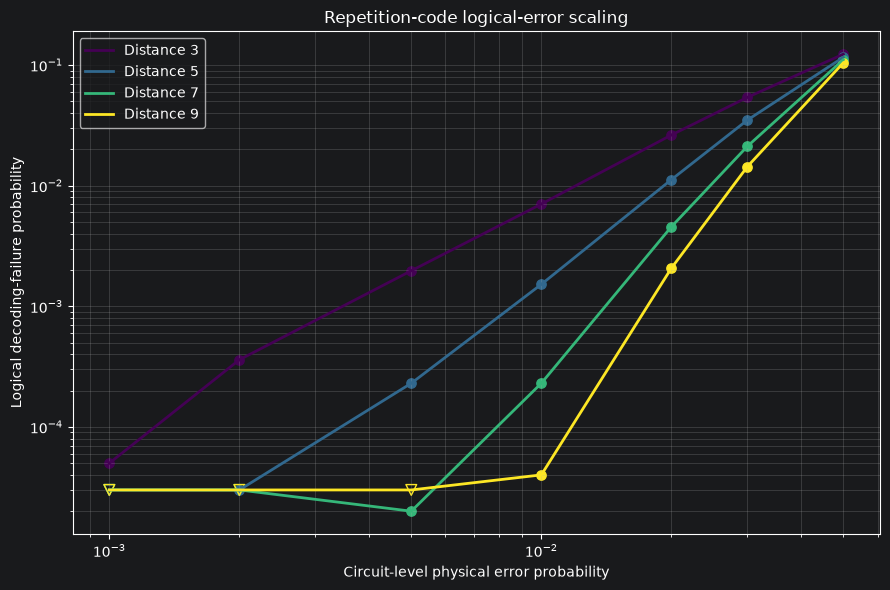

Saved figure to: C:\Users\Karthi\Qauntum\figures\stim_repetition_logical_error_scaling.png


In [161]:
# Plot log-log logical failure probability vs. physical error probability across code distances
figure, axis = plt.subplots(
    figsize=(9, 6)
)

colour_map = plt.get_cmap(
    "viridis"
)

for distance_index, distance in enumerate(
        distances
):
    subset = scaling_df[
        scaling_df[
            "distance"
        ] == distance
        ].sort_values(
        "physical_error_probability"
    )

    colour = colour_map(
        distance_index
        / max(
            1,
            len(distances) - 1,
        )
    )

    measured_subset = subset[
        ~subset[
            "used_upper_bound"
        ]
    ]

    upper_bound_subset = subset[
        subset[
            "used_upper_bound"
        ]
    ]

    axis.plot(
        subset[
            "physical_error_probability"
        ],
        subset[
            "logical_probability_for_plot"
        ],
        linewidth=2,
        color=colour,
        label=f"Distance {distance}",
    )

    axis.scatter(
        measured_subset[
            "physical_error_probability"
        ],
        measured_subset[
            "logical_failure_probability"
        ],
        marker="o",
        s=45,
        color=colour,
    )

    if not upper_bound_subset.empty:
        axis.scatter(
            upper_bound_subset[
                "physical_error_probability"
            ],
            upper_bound_subset[
                "logical_probability_for_plot"
            ],
            marker="v",
            s=60,
            facecolors="none",
            edgecolors=colour,
        )

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xlabel(
    "Circuit-level physical error probability"
)

axis.set_ylabel(
    "Logical decoding-failure probability"
)

axis.set_title(
    "Repetition-code logical-error scaling"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

logical_scaling_path = (
        FIGURE_DIR
        / "stim_repetition_logical_error_scaling.png"
)

figure.savefig(
    logical_scaling_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{logical_scaling_path}"
)

Open downward-pointing markers represent approximate 95% upper bounds from configurations in which no logical failures were observed. They are not direct measurements of a nonzero logical failure probability.


In [162]:
# Pivot logical failure probabilities by physical error rate (rows) and code distance (columns)
logical_probability_pivot = (
    scaling_df.pivot(
        index=(
            "physical_error_probability"
        ),
        columns="distance",
        values=(
            "logical_failure_probability"
        ),
    )
)

logical_probability_pivot

distance,3,5,7,9
physical_error_probability,,,,
0.001,0.00005,0.00000,0.00000,0.00000
0.002,0.00036,0.00003,0.00000,0.00000
0.005,0.00197,0.00023,0.00002,0.00000
0.010,0.00704,0.00152,0.00023,0.00004
0.020,0.02629,0.01121,0.00456,0.00207
0.030,0.05399,0.03498,0.02121,0.01440
0.050,0.12294,0.11585,0.11058,0.10433


In [163]:
# Compute error-suppression ratios comparing distance 3 against distances 5, 7, and 9
for distance in [
    5,
    7,
    9,
]:
    logical_probability_pivot[
        f"d3_divided_by_d{distance}"
    ] = (
            logical_probability_pivot[3]
            / logical_probability_pivot[
                distance
            ].replace(
        0.0,
        np.nan,
    )
    )

logical_probability_pivot

distance,3,5,7,9,d3_divided_by_d5,d3_divided_by_d7,d3_divided_by_d9
physical_error_probability,,,,,,,
0.001,0.00005,0.00000,0.00000,0.00000,NaN,NaN,NaN
0.002,0.00036,0.00003,0.00000,0.00000,12.000000,NaN,NaN
0.005,0.00197,0.00023,0.00002,0.00000,8.565217,98.500000,NaN
0.010,0.00704,0.00152,0.00023,0.00004,4.631579,30.608696,176.000000
0.020,0.02629,0.01121,0.00456,0.00207,2.345227,5.765351,12.700483
0.030,0.05399,0.03498,0.02121,0.01440,1.543453,2.545497,3.749306
0.050,0.12294,0.11585,0.11058,0.10433,1.061200,1.111774,1.178376


In [164]:
# Build a pairwise comparison table checking whether larger distances reduce logical error rates
distance_comparison_results = []

for physical_probability in (
        physical_error_probabilities
):
    subset = scaling_df[
        scaling_df[
            "physical_error_probability"
        ] == physical_probability
        ].sort_values(
        "distance"
    )

    probabilities = {
        int(row["distance"]): row[
            "logical_probability_for_plot"
        ]
        for row in subset.to_dict(
            orient="records"
        )
    }

    for smaller_distance, larger_distance in [
        (3, 5),
        (5, 7),
        (7, 9),
    ]:
        distance_comparison_results.append(
            {
                "physical_error_probability": (
                    physical_probability
                ),
                "smaller_distance": (
                    smaller_distance
                ),
                "larger_distance": (
                    larger_distance
                ),
                "smaller_distance_probability": (
                    probabilities[
                        smaller_distance
                    ]
                ),
                "larger_distance_probability": (
                    probabilities[
                        larger_distance
                    ]
                ),
                "larger_distance_improved": (
                        probabilities[
                            larger_distance
                        ]
                        < probabilities[
                            smaller_distance
                        ]
                ),
            }
        )

distance_comparison_df = pd.DataFrame(
    distance_comparison_results
)

distance_comparison_df

,physical_error_probability,smaller_distance,larger_distance,smaller_distance_probability,larger_distance_probability,larger_distance_improved
0,0.001,3,5,0.00005,0.00003,True
1,0.001,5,7,0.00003,0.00003,False
2,0.001,7,9,0.00003,0.00003,False
3,0.002,3,5,0.00036,0.00003,True
4,0.002,5,7,0.00003,0.00003,False
5,0.002,7,9,0.00003,0.00003,False
6,0.005,3,5,0.00197,0.00023,True
7,0.005,5,7,0.00023,0.00002,True
8,0.005,7,9,0.00002,0.00003,False
9,0.010,3,5,0.00704,0.00152,True


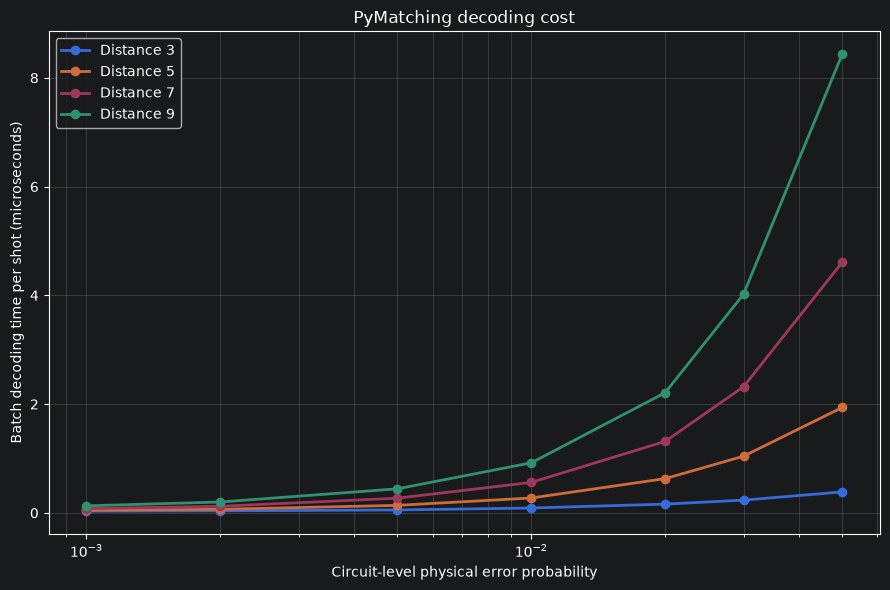

Saved figure to: C:\Users\Karthi\Qauntum\figures\pymatching_decoder_scaling.png


In [165]:
# Plot mean batch decoding time per shot vs. physical error rate across code distances
figure, axis = plt.subplots(
    figsize=(9, 6)
)

for distance in distances:
    subset = scaling_df[
        scaling_df[
            "distance"
        ] == distance
        ].sort_values(
        "physical_error_probability"
    )

    axis.plot(
        subset[
            "physical_error_probability"
        ],
        subset[
            "decoder_microseconds_per_shot"
        ],
        marker="o",
        linewidth=2,
        label=f"Distance {distance}",
    )

axis.set_xscale("log")

axis.set_xlabel(
    "Circuit-level physical error probability"
)

axis.set_ylabel(
    "Batch decoding time per shot "
    "(microseconds)"
)

axis.set_title(
    "PyMatching decoding cost"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

decoder_scaling_path = (
        FIGURE_DIR
        / "pymatching_decoder_scaling.png"
)

figure.savefig(
    decoder_scaling_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{decoder_scaling_path}"
)

In [166]:
# Extract unique circuit and matching-graph dimensions for each code distance
graph_size_df = (
    scaling_df[
        [
            "distance",
            "rounds",
            "qubits",
            "detectors",
            "matching_edges",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        "distance"
    )
)

graph_size_df

,distance,rounds,qubits,detectors,matching_edges
0,3,3,5,8,21
7,5,5,9,24,65
14,7,7,13,48,133
21,9,9,17,80,225


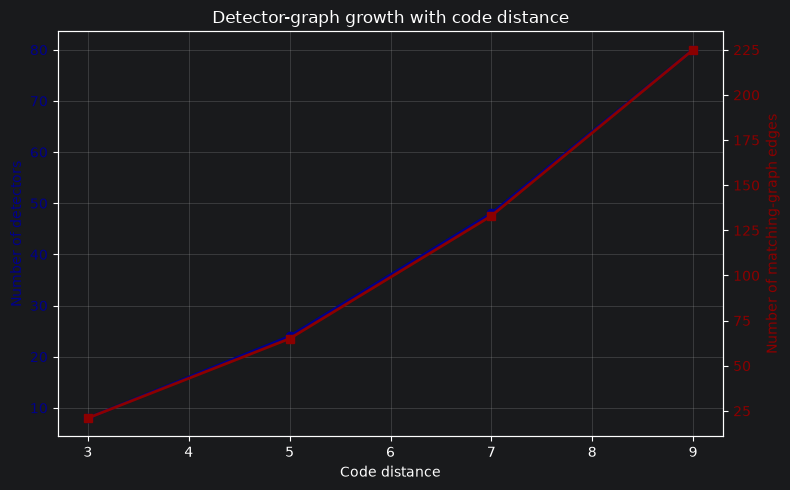

Saved figure to: C:\Users\Karthi\Qauntum\figures\repetition_detector_graph_scaling.png


In [167]:
# Plot detector node count and matching-graph edge count vs. code distance using dual y-axes
figure, primary_axis = plt.subplots(
    figsize=(8, 5)
)

primary_axis.plot(
    graph_size_df["distance"],
    graph_size_df["detectors"],
    marker="o",
    linewidth=2,
    color="darkblue",
    label="Detectors",
)

primary_axis.set_xlabel(
    "Code distance"
)

primary_axis.set_ylabel(
    "Number of detectors",
    color="darkblue",
)

primary_axis.tick_params(
    axis="y",
    labelcolor="darkblue",
)

secondary_axis = (
    primary_axis.twinx()
)

secondary_axis.plot(
    graph_size_df["distance"],
    graph_size_df["matching_edges"],
    marker="s",
    linewidth=2,
    color="darkred",
    label="Matching edges",
)

secondary_axis.set_ylabel(
    "Number of matching-graph edges",
    color="darkred",
)

secondary_axis.tick_params(
    axis="y",
    labelcolor="darkred",
)

primary_axis.set_title(
    "Detector-graph growth with code distance"
)

primary_axis.grid(
    True,
    alpha=0.3,
)

figure.tight_layout()

graph_size_path = (
        FIGURE_DIR
        / "repetition_detector_graph_scaling.png"
)

figure.savefig(
    graph_size_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{graph_size_path}"
)

In [168]:
# Configure parameters for the single-shot decoder latency benchmark (d=7, r=7, p=1%)
latency_distance = 7
latency_rounds = 7
latency_probability = 0.01
latency_shots = 2_000

In [169]:
# Build circuit, MWPM decoder, and sample 2,000 syndrome shots for latency testing
latency_circuit = (
    create_repetition_memory_circuit(
        distance=latency_distance,
        rounds=latency_rounds,
        physical_error_probability=(
            latency_probability
        ),
    )
)

latency_detector_error_model = (
    latency_circuit.detector_error_model(
        decompose_errors=True
    )
)

latency_decoder = (
    pymatching.Matching
    .from_detector_error_model(
        latency_detector_error_model
    )
)

latency_sampler = (
    latency_circuit
    .compile_detector_sampler(
        seed=SEED + 100_000
    )
)

latency_detection_events, _ = (
    latency_sampler.sample(
        shots=latency_shots,
        separate_observables=True,
    )
)

In [170]:
# Warm up PyMatching single-shot decode call before timing
latency_decoder.decode(
    latency_detection_events[0]
)

array([0], dtype=uint8)

In [171]:
# Measure individual single-shot decoding latencies in microseconds
single_shot_latencies_microseconds = []

for detection_sample in (
        latency_detection_events
):
    start_time = perf_counter()

    latency_decoder.decode(
        detection_sample
    )

    end_time = perf_counter()

    single_shot_latencies_microseconds.append(
        1e6
        * (
                end_time - start_time
        )
    )

single_shot_latencies_microseconds = (
    np.asarray(
        single_shot_latencies_microseconds
    )
)

In [172]:
# Compute mean, median, 95th/99th percentiles, and maximum single-shot latency
latency_summary = {
    "mean_microseconds": float(
        np.mean(
            single_shot_latencies_microseconds
        )
    ),
    "median_microseconds": float(
        np.median(
            single_shot_latencies_microseconds
        )
    ),
    "p95_microseconds": float(
        np.percentile(
            single_shot_latencies_microseconds,
            95,
        )
    ),
    "p99_microseconds": float(
        np.percentile(
            single_shot_latencies_microseconds,
            99,
        )
    ),
    "maximum_microseconds": float(
        np.max(
            single_shot_latencies_microseconds
        )
    ),
}

pd.Series(latency_summary)

mean_microseconds        3.661250
median_microseconds      3.499910
p95_microseconds         4.999922
p99_microseconds         6.499934
maximum_microseconds    29.599993
dtype: float64

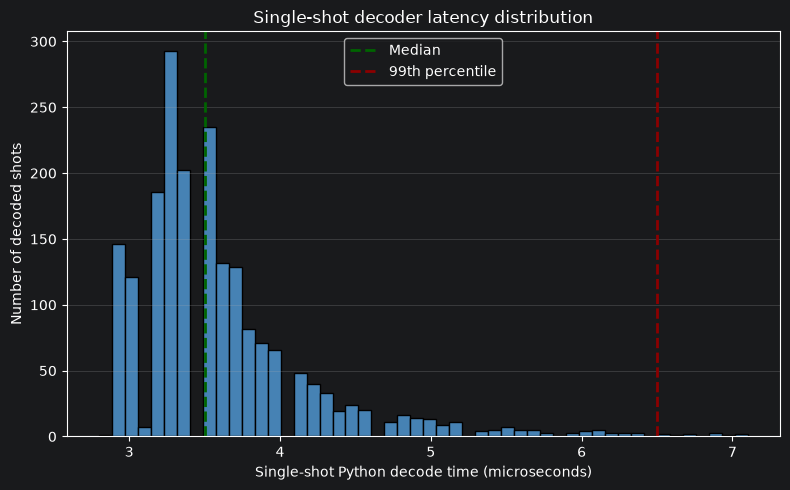

Saved figure to: C:\Users\Karthi\Qauntum\figures\pymatching_single_shot_latency.png


In [173]:
# Plot and save the single-shot latency histogram (trimmed at the 99.5th percentile)
upper_plot_limit = np.percentile(
    single_shot_latencies_microseconds,
    99.5,
)

trimmed_latencies = (
    single_shot_latencies_microseconds[
        single_shot_latencies_microseconds
        <= upper_plot_limit
        ]
)

figure, axis = plt.subplots(
    figsize=(8, 5)
)

axis.hist(
    trimmed_latencies,
    bins=50,
    color="steelblue",
    edgecolor="black",
)

axis.axvline(
    latency_summary[
        "median_microseconds"
    ],
    color="darkgreen",
    linestyle="--",
    linewidth=2,
    label="Median",
)

axis.axvline(
    latency_summary[
        "p99_microseconds"
    ],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="99th percentile",
)

axis.set_xlabel(
    "Single-shot Python decode time "
    "(microseconds)"
)

axis.set_ylabel(
    "Number of decoded shots"
)

axis.set_title(
    "Single-shot decoder latency distribution"
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

latency_distribution_path = (
        FIGURE_DIR
        / "pymatching_single_shot_latency.png"
)

figure.savefig(
    latency_distribution_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{latency_distribution_path}"
)

In [174]:
# Export all scaling sweep tables and latency benchmark results to CSV files
scaling_results_path = (
        RESULTS_DIR
        / "stim_repetition_scaling_results.csv"
)

scaling_df.to_csv(
    scaling_results_path,
    index=False,
)

distance_comparison_path = (
        RESULTS_DIR
        / "stim_repetition_distance_comparison.csv"
)

distance_comparison_df.to_csv(
    distance_comparison_path,
    index=False,
)

graph_size_path_csv = (
        RESULTS_DIR
        / "stim_repetition_graph_sizes.csv"
)

graph_size_df.to_csv(
    graph_size_path_csv,
    index=False,
)

latency_results_df = pd.DataFrame(
    {
        "latency_microseconds": (
            single_shot_latencies_microseconds
        )
    }
)

latency_results_path = (
        RESULTS_DIR
        / "pymatching_single_shot_latencies.csv"
)

latency_results_df.to_csv(
    latency_results_path,
    index=False,
)

latency_summary_df = pd.DataFrame(
    [
        {
            "distance": latency_distance,
            "rounds": latency_rounds,
            "physical_error_probability": (
                latency_probability
            ),
            "shots": latency_shots,
            **latency_summary,
        }
    ]
)

latency_summary_path = (
        RESULTS_DIR
        / "pymatching_latency_summary.csv"
)

latency_summary_df.to_csv(
    latency_summary_path,
    index=False,
)

print(
    f"Saved scaling data to: "
    f"{scaling_results_path}"
)

print(
    f"Saved latency summary to: "
    f"{latency_summary_path}"
)

Saved scaling data to: C:\Users\Karthi\Qauntum\results\stim_repetition_scaling_results.csv
Saved latency summary to: C:\Users\Karthi\Qauntum\results\pymatching_latency_summary.csv


# Scaling results


The circuit-level simulations compared repetition-code distances 3, 5, 7 and 9, with the number of syndrome-extraction rounds set equal to the code distance.


At sufficiently low physical error probabilities, increasing code distance reduced the logical decoding-failure probability. The larger code uses additional physical qubits and parity checks to distinguish a greater number of physical faults.


The benefit of increasing the distance was not necessarily uniform across all simulated physical error probabilities. Near a threshold or curve-crossing region, statistical uncertainty and finite code size make the ordering less distinct. A more rigorous threshold estimate would require additional distances, denser sampling near the crossing and substantially more shots.


Some low-error configurations may produce no observed logical failures. These cases were plotted using the rule-of-three 95% upper bound rather than as zero-valued measurements. A zero-failure sample provides only an upper bound on the true failure probability.


The decoding benchmark showed both the growth of the matching graph and the increase in classical decoding work with code distance. The number of detection events also increased with physical error probability, potentially increasing the complexity of individual matching problems.


Batch decoding time measures aggregate software throughput. It does not directly measure real-time single-shot latency. The separate latency experiment displayed the median, 95th-percentile and 99th-percentile decode times, but these measurements include Python call overhead and operating-system scheduling effects.


A real-time fault-tolerant system must satisfy a latency or backlog constraint as well as achieving a sufficiently low logical failure probability. This creates a co-design problem involving the code, syndrome-extraction schedule, decoder algorithm and classical hardware.
